In [13]:
#Para el código es necesario instalar la librería pyvrp
# pip install pyvrp



In [14]:

import numpy as np
from pyvrp import Model
from pyvrp . stop import MaxRuntime
from pyvrp.plotting import plot_coordinates,plot_solution,plot_diversity, plot_objectives, plot_runtimes, plot_route_schedule


In [15]:

m=Model() #Creación dle modelo

#Puntos de abastecimiento y Destinos
#Coordenadas x,y para visualizar el problema
#  tw_early y tw_late es la ventana de tiempo en minutos
# delivery es la demanda
# service_duration es el tiempo de servicio

m.add_depot(x=2, y=0, tw_early=420, tw_late= 900, name= 'abast_1') 

m.add_depot(x=2, y=-4, tw_early=480, tw_late= 960, name= 'abast_2')

m.add_client(x=0, y=0, delivery=4, tw_early=480, tw_late=720, service_duration=25, name='destino_1')

m.add_client(x=4, y=0, delivery=3, tw_early=540, tw_late=780, service_duration=20, name='destino_2')

m.add_client(x=4, y=-5, delivery=5, tw_early=600, tw_late=840, service_duration=30, name='destino_3')



In [16]:
#Vehiculos
# se agrupan según capacidad, puntos de recarga u otros criterios
# capacity es capacidad de carga del tipo de vehiculo
# num_available es el numero de vehiculo del tipo
#start_depot y end_depot son los puntos de abastecimiento donde parte y termina el tipo de vehiculo
#reload_depots son los puntos de abasticimiento donde el vehiculo puede recargar su carga

m.add_vehicle_type(capacity=5, num_available=1, start_depot=m.locations[0], end_depot=m.locations[0], reload_depots=[m.locations[0], m.locations[1]], name='camion_1')

m.add_vehicle_type(capacity=8, num_available=1, start_depot=m.locations[0], end_depot=m.locations[0], reload_depots=[m.locations[0], m.locations[1]], name='camion_2')

In [17]:
#Matriz de distancias
Distancias=[ 
    [0, 20, 5, 6, 35],
    [20, 0, 30, 22, 8],
    [5, 30, 0, 13, 45],
    [6, 22, 13, 0, 30],
    [35, 8, 45, 30, 0]
]


In [18]:
#Creacion de las rutas entre todos los nodos usando la matriz de distancias

for frm_idx, frm in enumerate(m.locations):
    for to_idx, to in enumerate(m.locations):
        m.add_edge(frm, to, distance=Distancias[frm_idx][to_idx])

In [19]:
#Solución según la librería
res = m. solve ( stop = MaxRuntime (1) , seed = 3) # un segundo


PyVRP v0.11.3

Solving an instance with:
    2 depots
    3 clients
    2 vehicles (2 vehicle types)

                  |       Feasible        |      Infeasible
    Iters    Time |   #      Avg     Best |   #      Avg     Best
H     500      0s |  32       76       74 |  63       76       74
     1000      0s |  40       77       74 |  27       80       74
     1500      1s |  37       76       74 |  39       78       74
     2000      1s |  60       76       74 |  25       80       74

Search terminated in 1.00s after 2083 iterations.
Best-found solution has cost 74.

Solution results
    # routes: 2
     # trips: 3
   # clients: 3
   objective: 74
    distance: 74
    duration: 75
# iterations: 2083
    run-time: 1.00 seconds



In [20]:
print (res)

Solution results
    # routes: 2
     # trips: 3
   # clients: 3
   objective: 74
    distance: 74
    duration: 75
# iterations: 2083
    run-time: 1.00 seconds

Routes
------
Route #1: 2
Route #2:  | 4 3



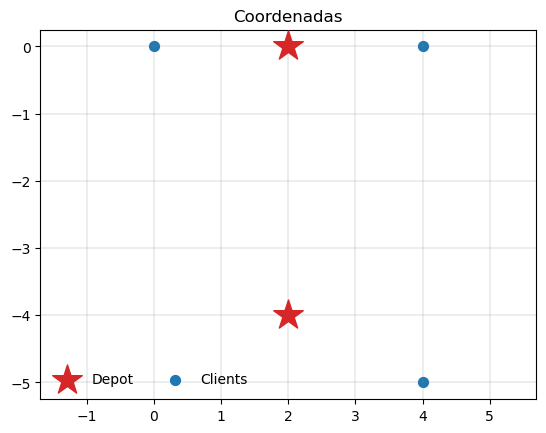

In [21]:
plot_coordinates(data=m.data(),title='Coordenadas') #Gráfica de coordenadas

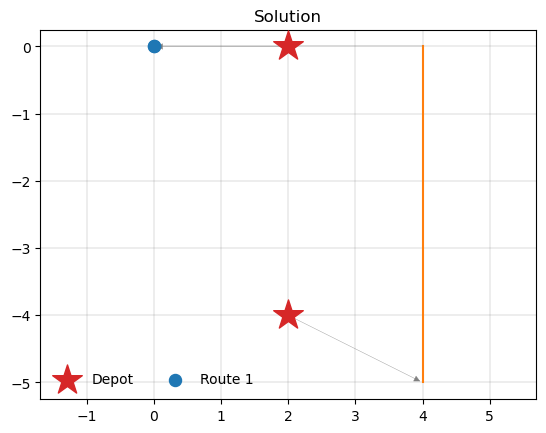

In [22]:
plot_solution(res.best, data=m.data()) #Gráfica de rutas

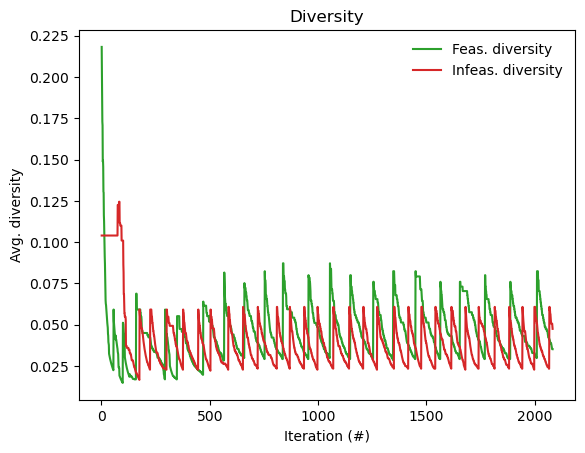

In [23]:
plot_diversity(res) #Gráfico de Diversidad 

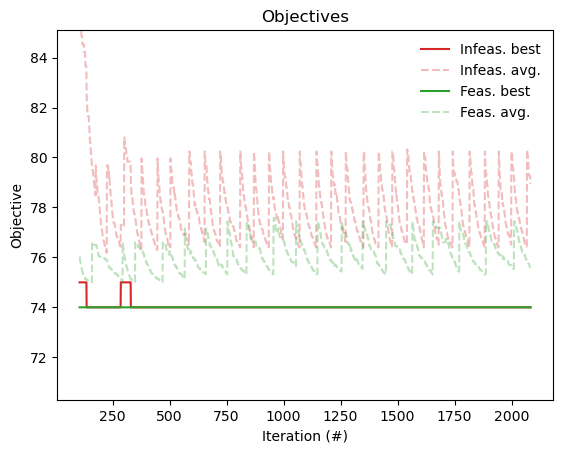

In [24]:
plot_objectives(res) #Gráfico de Función Objetivo

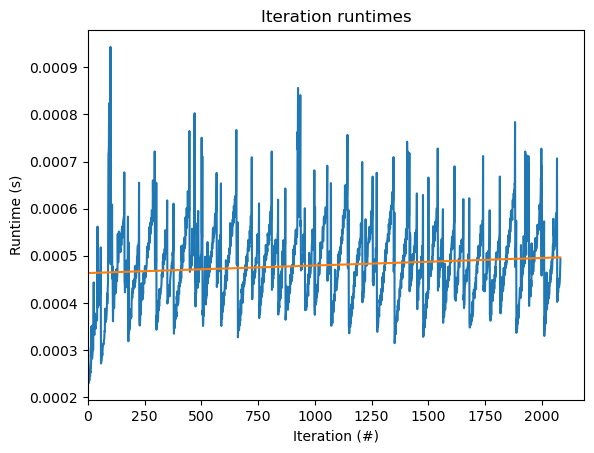

In [25]:
plot_runtimes(res) #Gráfico de tiempos de ejecución